# Review the Completed VGG16 Results

Nalacherla Shravan Kumar · 23EG110C43 · Roll 43.

This notebook reads the completed full-run files. **It does not train the model.** Use the Crop Weed VGG16 kernel and Run All to review results quickly. The main VGG16 notebook contains the full training workflow.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
import numpy as np
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'scripts/core.py').exists())
OUTPUT = ROOT/'outputs'
print('Project:', ROOT)

Project: C:\Users\shrav\Desktop\dl study proect\CNN-Crop-and-Weed-Classification


## Test summary
The model was selected using validation loss. These metrics come from the held-out test partition, not the smoke test.

In [2]:
results = json.loads((OUTPUT/'results_summary.json').read_text())
assert results['status'] == 'full_training_completed'
display(pd.DataFrame({'Metric':['Test accuracy','Test loss','ROC AUC','Test images','Measured epochs','Batch size'], 'Value':[results['test_accuracy'],results['test_loss'],results['auc'],results['evaluated_test_images'],results['epochs'],results['batch_size']]}))
print(f"Test accuracy: {results['test_accuracy']:.2%}")

,Metric,Value
0,Test accuracy,0.977136
1,Test loss,0.076002
2,ROC AUC,0.991821
3,Test images,831.000000
4,Measured epochs,5.000000
5,Batch size,4.000000


Test accuracy: 97.71%


## Verified partitions
Training updates weights, validation selects checkpoints, and test data measures the selected model. Paths are disjoint; plant identities may still overlap across growth stages.

In [3]:
splits = pd.read_csv(OUTPUT/'dataset_splits.csv')
display(splits.groupby(['split','label']).size().unstack().rename(columns={0:'Crop',1:'Weed'}))
assert not splits.relative_path.duplicated().any()
assert len(splits) == 5539

label,Crop,Weed
split,,
test,146,685
train,681,3196
validation,146,685


## Accuracy and epoch values
Blue and orange curves represent training and validation. Test accuracy is reported separately.

,accuracy,loss,val_accuracy,val_loss,learning_rate,epoch
0,0.776116,0.606164,0.883273,0.272548,0.00100,1
1,0.860459,0.332419,0.807461,0.522340,0.00100,2
2,0.875935,0.304568,0.918171,0.176035,0.00100,3
3,0.929585,0.187387,0.941035,0.160020,0.00001,4
4,0.950735,0.125231,0.971119,0.067408,0.00001,5


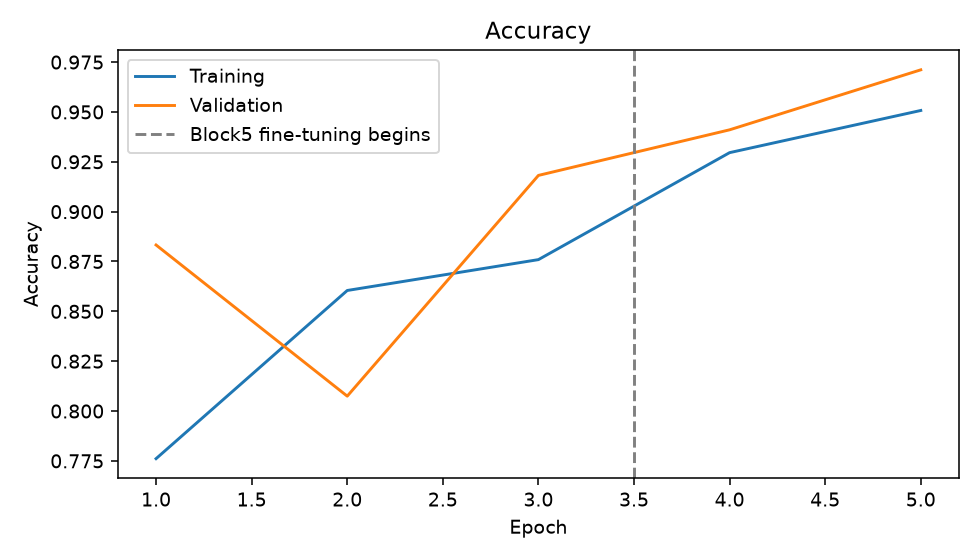

In [4]:
history = json.loads((OUTPUT/'training_history.json').read_text())
display(pd.DataFrame(history).assign(epoch=lambda f: np.arange(1,len(f)+1)))
display(Image(filename=str(OUTPUT/'accuracy_graph.png')))

## Loss
Training loss uses class weights. Validation loss is unweighted. The best validation loss selects the checkpoint across both phases.

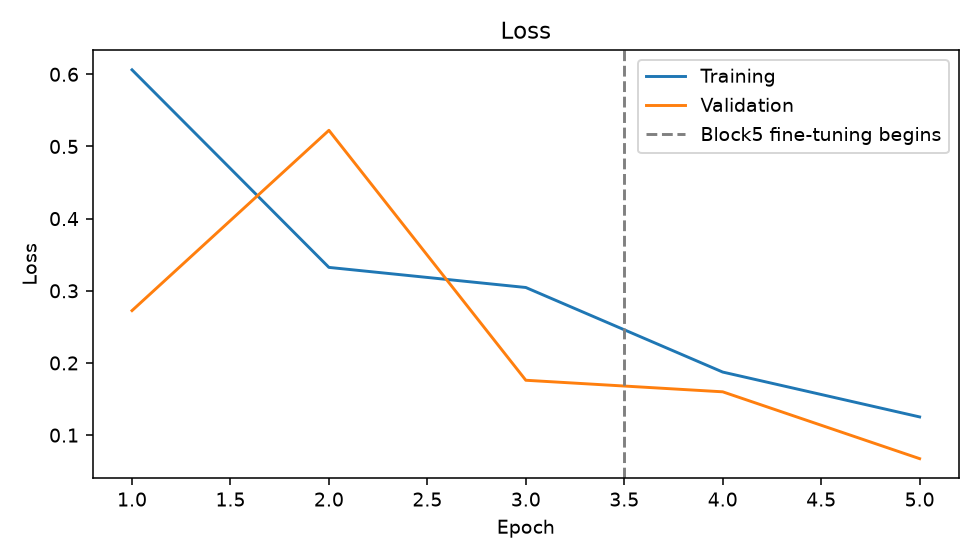

In [5]:
display(Image(filename=str(OUTPUT/'loss_graph.png')))

## Confusion matrix and class metrics
Rows are actual labels and columns are predicted labels. Inspect Crop recall as well as overall accuracy.

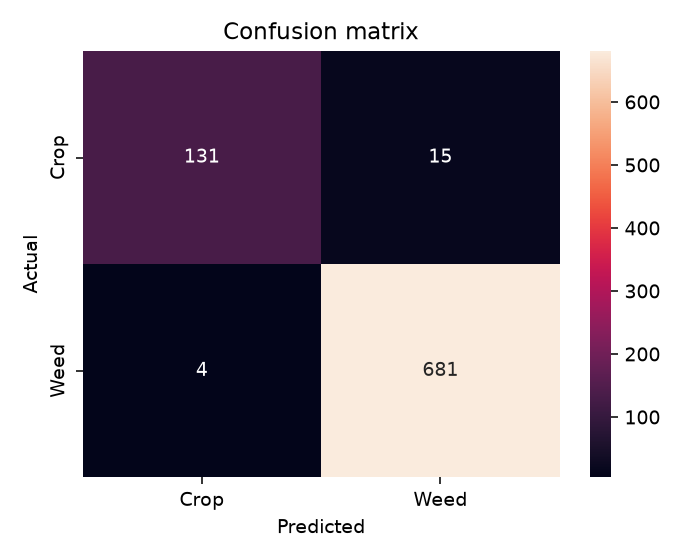

,precision,recall,f1-score,support
Crop,0.970370,0.897260,0.932384,146.0
Weed,0.978448,0.994161,0.986242,685.0
macro avg,0.974409,0.945710,0.959313,831.0
weighted avg,0.977029,0.977136,0.976780,831.0


In [6]:
display(Image(filename=str(OUTPUT/'confusion_matrix.png')))
display(pd.read_csv(OUTPUT/'classification_report.csv',index_col=0))

## Actual prediction examples and errors
These are saved predictions for test images. A sigmoid score is not a calibrated guarantee.

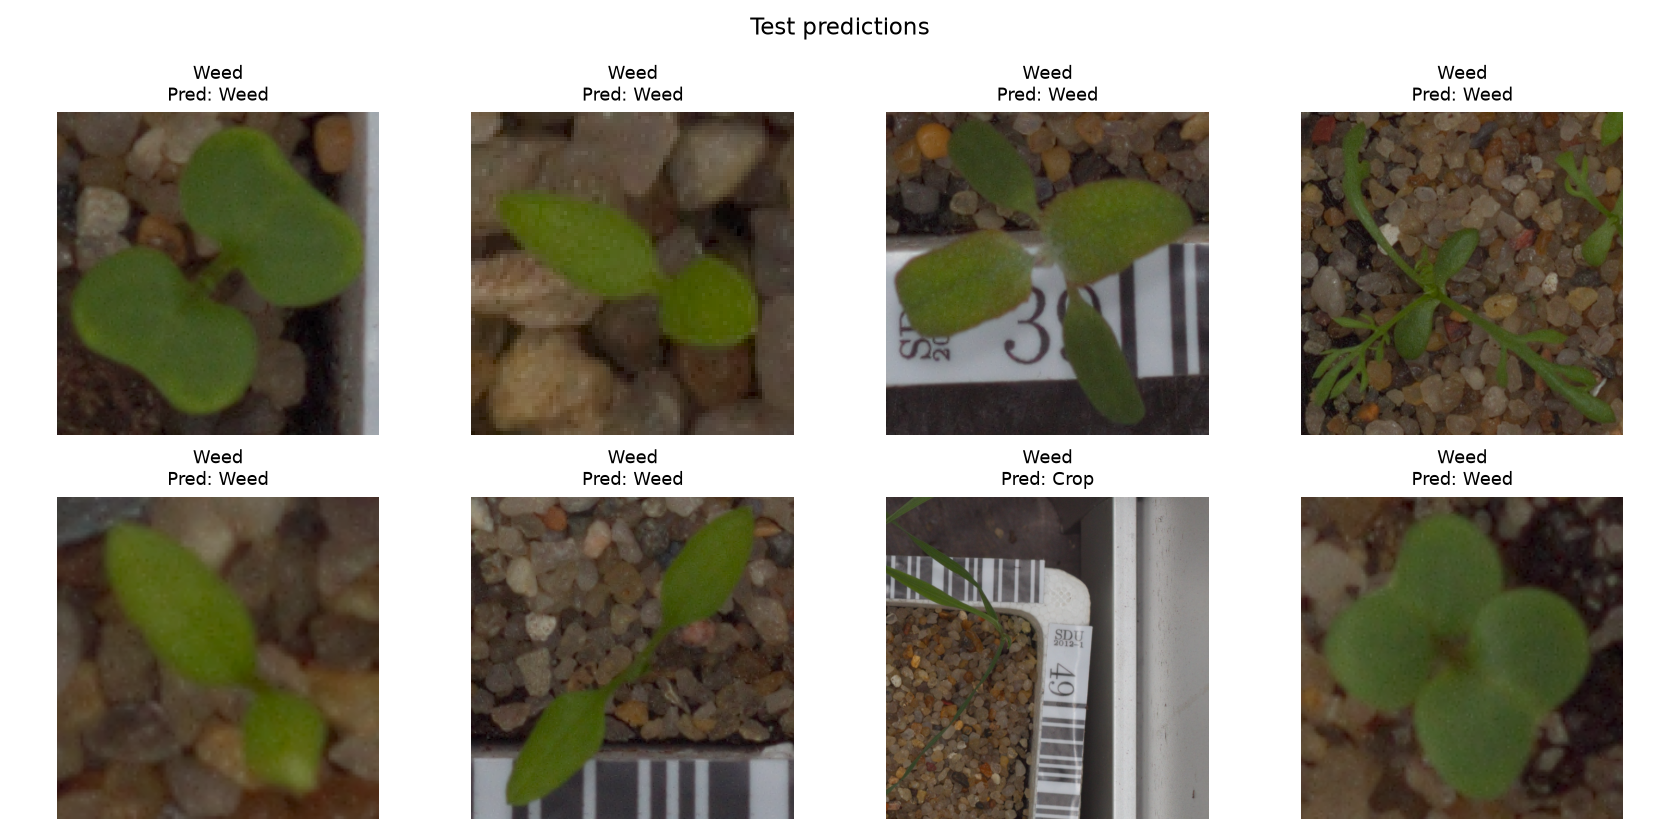

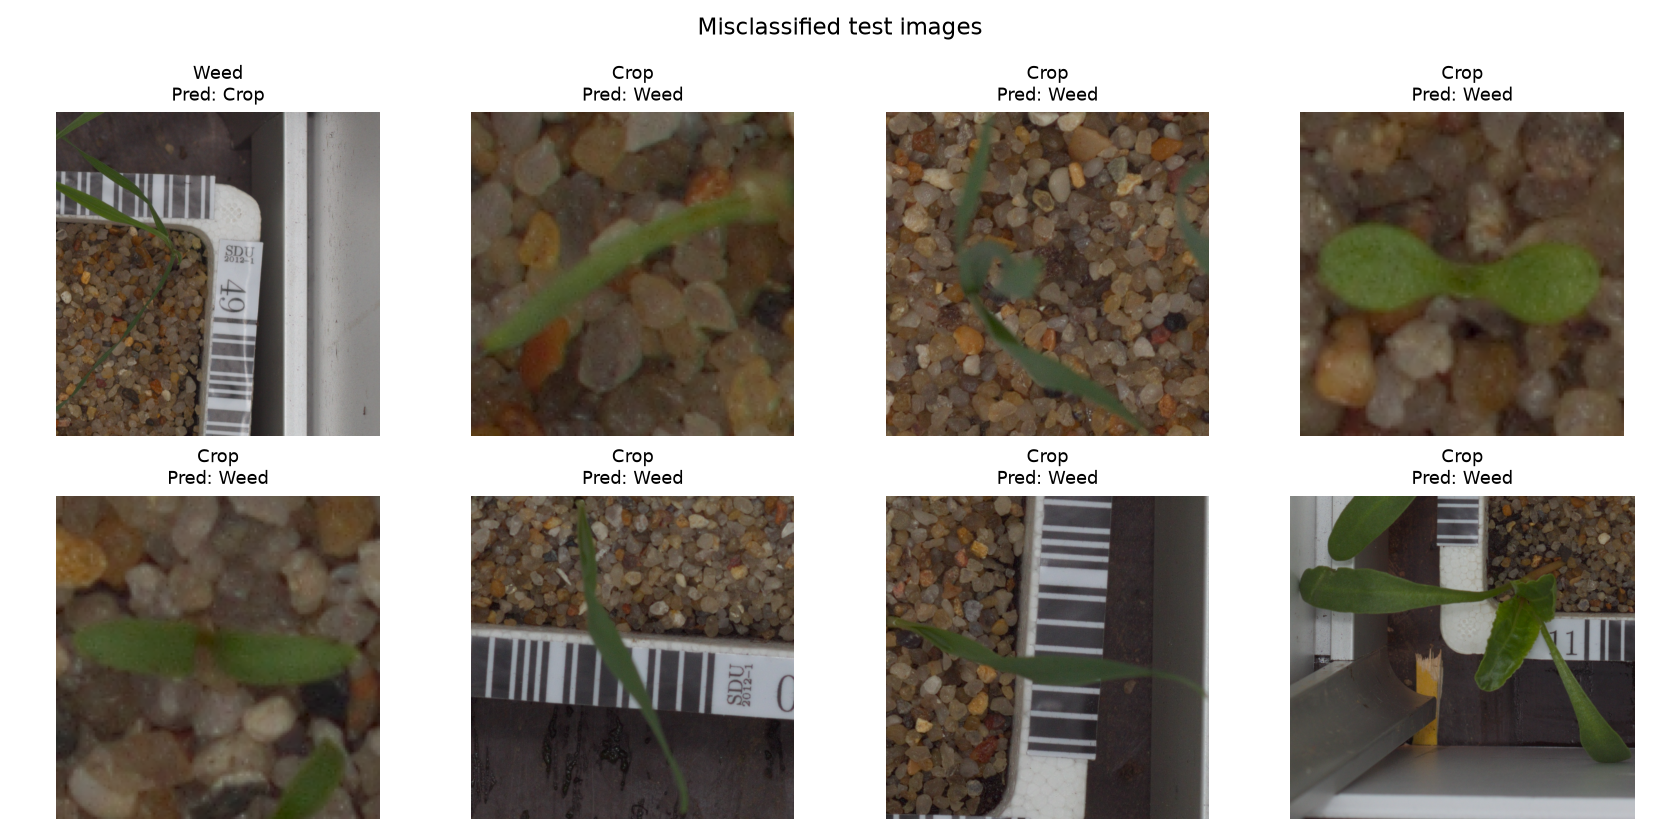

In [7]:
display(Image(filename=str(OUTPUT/'sample_predictions.png')))
display(Image(filename=str(OUTPUT/'misclassified_examples.png')))

## Every test prediction
The CSV records the original image path, species, actual label, score and predicted label.

In [8]:
predictions = pd.read_csv(OUTPUT/'test_predictions.csv')
assert len(predictions) == results['evaluated_test_images']
assert set(predictions.relative_path) == set(splits.loc[splits.split=='test','relative_path'])
display(predictions.head(10))
print('Correct predictions:', (predictions.label == predictions.predicted_label).sum())

,relative_path,species,label,split,weed_probability,predicted_label,predicted_class
0,data/raw/plant_seedlings/Charlock/285.png,Charlock,1,test,0.998870,1,Weed
1,data/raw/plant_seedlings/Common Chickweed/295.png,Common Chickweed,1,test,0.999982,1,Weed
2,data/raw/plant_seedlings/Fat Hen/391.png,Fat Hen,1,test,1.000000,1,Weed
3,data/raw/plant_seedlings/Scentless Mayweed/130...,Scentless Mayweed,1,test,1.000000,1,Weed
4,data/raw/plant_seedlings/Common Chickweed/309.png,Common Chickweed,1,test,0.999932,1,Weed
5,data/raw/plant_seedlings/Common Chickweed/657.png,Common Chickweed,1,test,0.997446,1,Weed
6,data/raw/plant_seedlings/Black-grass/76.png,Black-grass,1,test,0.226539,0,Crop
7,data/raw/plant_seedlings/Charlock/129.png,Charlock,1,test,0.999973,1,Weed
8,data/raw/plant_seedlings/Small-flowered Cranes...,Small-flowered Cranesbill,1,test,1.000000,1,Weed
9,data/raw/plant_seedlings/Cleavers/151.png,Cleavers,1,test,0.959474,1,Weed


Correct predictions: 812


## Reload the saved model and check one prediction
This final cell performs inference only. It checks that a single-image prediction matches the saved test score. The checkpoint and raw data remain local, so the cell skips inference on a fresh clone that does not contain those files.

In [9]:
model_path = ROOT/'models/best_vgg16_crop_weed.keras'
row = predictions.loc[predictions.label==0].iloc[0]
image_path = ROOT/row.relative_path
if model_path.exists() and image_path.exists():
    import tensorflow as tf
    tf.config.threading.set_intra_op_parallelism_threads(2)
    tf.config.threading.set_inter_op_parallelism_threads(1)
    sys.path.insert(0,str(ROOT/'scripts'))
    from core import predict_image
    model = tf.keras.models.load_model(model_path,compile=False)
    prediction = predict_image(model,image_path)
    np.testing.assert_allclose(prediction['weed_probability'], row.weed_probability, rtol=1e-4, atol=1e-5)
    assert prediction['class'] == row.predicted_class
    print('Actual label: Crop')
    print(prediction)
else:
    print('Graphs and metrics reviewed. The local checkpoint and raw image are required for inference.')

Actual label: Crop
{'class': 'Crop', 'weed_probability': 3.6301273212302476e-05}


## What to study next
Read docs/Project_Explained_From_Zero.md or the Word study guide. Use the results presentation for the eleven-slide talk. Remember the image-level split and controlled-background limitations.